# PHYS 2550 - Homework 2

Run the cells from top to bottom. Written answers are also in [Report.md](Report.md).
The dataset is in `data/`; saved training runs are in `results/`.


## Part 1 - Theory


### T1. Counting parameters

I counted biases using $(n_{\rm in}+1)n_{\rm out}$ for dense layers and $(k_hk_wC_{\rm in}+1)C_{\rm out}$ for convolutions. Dense layers are numbered within each model.

| Layer | CNN | FCNN-matched | FCNN-large |
|---|---:|---:|---:|
| Conv 1 | 448 | -- | -- |
| Conv 2 | 4,640 | -- | -- |
| Conv 3 | 18,496 | -- | -- |
| Dense 1 | 147,520 | 165,912 | 1,769,728 |
| Dense 2 | 650 | 1,600 | 32,896 |
| Dense 3 | -- | 650 | 1,290 |
| **Total** | **171,754** | **168,162** | **1,803,914** |

ReLU, pooling, flattening, and dropout add no parameters. The CNN's first dense layer holds $147520/171754\approx85.9\%$ of the total. FCNN-matched has $6977h+714$ parameters: 24 nodes fit the budget, but 25 give 175,139. The CNN saves parameters by reusing filters.


### T2(a). Convolution by hand

Each output is five times the center minus its four neighbors. For example, the top-left value is $5(3)-2-0-1-1=11$. The output is $3\times3$:

$$I*K=\begin{pmatrix}11&-4&6\\-4&15&-4\\-5&2&9\end{pmatrix}.$$


### T2(b). Output sizes

For input size $n$, kernel $k$, padding $p$, and stride $s$,

$$n_{\rm out}=\left\lfloor\frac{n+2p-k}{s}\right\rfloor+1.$$

Padding 1 and stride 1 give $5\times5$. Stride 2 without padding gives $2\times2$.


### T2(c). Pooling

Using $2\times2$ windows with stride 1:

$$P_{\max}=\begin{pmatrix}15&15\\15&15\end{pmatrix},\qquad P_{\rm avg}=\begin{pmatrix}4.5&3.25\\2&5.5\end{pmatrix}.$$

Moving the bright pixel moves the response. Max pooling can stay unchanged if the peak stays in its window; average pooling uses all four values. Neither is always unchanged by a shift.


### T2(d). Background and noise

The weights sum to 1, so a constant background stays unchanged. For independent noise,

$$\operatorname{Var}(I*K)=\sigma^2\sum_{ij}K_{ij}^2=29\sigma^2.$$

The noise standard deviation grows by $\sqrt{29}\approx5.39$. Sharpening can therefore make noise look like features in faint galaxies.


### T2(e). Cross-correlation

This kernel is unchanged by a $180^\circ$ rotation. A learned kernel can just learn the flipped weights, so either convention can represent the same filters.


### T3(a). Shapes through the CNN

Shapes are height × width × channels. Layers grouped together have the same output shape.

| Layer | Output shape |
|---|---|
| Input | $48\times48\times3$ |
| Conv 1, ReLU | $48\times48\times16$ |
| Pool 1 | $24\times24\times16$ |
| Conv 2, ReLU | $24\times24\times32$ |
| Pool 2 | $12\times12\times32$ |
| Conv 3, ReLU | $12\times12\times64$ |
| Pool 3 | $6\times6\times64$ |
| Flatten | $2304$ |
| Dense 64, ReLU, dropout | $64$ |
| Dense 10 | $10$ logits |


### T3(b). Receptive field

Starting at $(r,j)=(1,1)$, the receptive-field width and spacing update as $r'=r+(k-1)j$ and $j'=sj$.

| Layer | Conv 1 | Pool 1 | Conv 2 | Pool 2 | Conv 3 | Pool 3 |
|---|---:|---:|---:|---:|---:|---:|
| $r$ | 3 | 4 | 8 | 10 | **18** | 22 |
| $j$ | 1 | 2 | 2 | 4 | 4 | 8 |

The third convolution sees $18\times18$ pixels, less than a 20–40-pixel galaxy. The last pool sees 22 pixels, enough for a small galaxy in the right position. The dense layer combines information across the whole image.


### T3(c). Strided first convolution

With stride 2 and no padding, $\lfloor(48-3)/2\rfloor+1=23$, giving **$23\times23\times16$**.


### T4(a). Equivariance and invariance

Equivariance means the output shifts with the input; invariance means it stays unchanged. With $(T_\delta x)(u)=x(u-\delta)$, these are $f(T_\delta x)=T_\delta f(x)$ and $f(T_\delta x)=f(x)$. Ignoring boundaries, a stride-1 convolution gives

$$f(T_\delta x)(u)=b+\sum_vK(v)x(u+v-\delta)=f(x)(u-\delta)=T_\delta f(x)(u).$$


### T4(b). Approximate invariance

Pooling can keep a peak when it moves within a window. Crossing windows, padding at the edges, and the dense layer's different weights at different positions stop this from being exact invariance.


### T4(c). Shift prediction

An FCNN has separate weights at each position, so neither property is built in. I expect shifts to reduce accuracy for all models, but less for the CNN. Large shifts also cut off light.


### T5. Scrambled pixels

If the input becomes $xP$, the FCNN can use first-layer weights $P^TW$, since

$$(xP)(P^TW)=xW.$$

I expect similar FCNN accuracy after retraining. The CNN assumes nearby pixels form useful patterns; scrambling breaks these, so I expect it to do worse. The same shuffle must be used for every image and all channels.


### T6(a). Forward-pass MACs

I count one multiply–accumulate as one MAC, leaving out biases, activations, and pooling comparisons.

| CNN layer | MACs per image |
|---|---:|
| Conv 1: $48^2\cdot16\cdot27$ | 995,328 |
| Conv 2: $24^2\cdot32\cdot144$ | 2,654,208 |
| Conv 3: $12^2\cdot64\cdot288$ | 2,654,208 |
| Dense 64: $2304\cdot64$ | 147,456 |
| Dense 10: $64\cdot10$ | 640 |
| **Total** | **6,451,840** |

FCNN-matched uses $6912\cdot24+24\cdot64+64\cdot10=168,064$ MACs. FCNN-large uses $6912\cdot256+256\cdot128+128\cdot10=1,803,520$.


### T6(b). Cost per step

The CNN uses $6451840/168064\approx38.4$ times as many forward MACs. Backpropagation adds similar-order work. Shared weights still get applied at many positions, so fewer parameters don't mean less work. The time ratio depends on hardware.


### T6(c). Training speed

A CNN might need fewer epochs to reach the same accuracy, but each epoch costs more. I would compare seconds per epoch, epochs and total time to a common validation target, and which runs fail to reach it.


### T7(a). Average pooling

For four independent pixels, $A=(X_1+X_2+X_3+X_4)/4$:

$$\mathbb E[A]=\mu,\qquad\operatorname{Var}(A)=\frac{4\sigma^2}{16}=\frac{\sigma^2}{4},\qquad\sigma_A=\frac{\sigma}{2}.$$


### T7(b). Max pooling

It picks upward fluctuations, so it is biased high. For Gaussian noise, $\mathbb E[\max_iX_i]\approx\mu+1.03\sigma$.


### T7(c). Choice of pooling

I would try average pooling for faint galaxies: it reduces independent noise while keeping their spread-out light. Max pooling can pick noise spikes. For a dark object on a bright background, I would use min pooling.


### T8(a). Training curves

FCNN-large starts overfitting around **epoch 8**, which early stopping would keep. Patience 5 would stop training about five epochs later. The CNN shows no clear overfitting or underfitting; a plateau alone doesn't show underfitting.


### T8(b). Reducing the gap

I would try weight decay to discourage large weights, plus rotations and flips so the model sees more valid orientations. I would tune these using validation performance.


### T8(c). Smaller CNN gap

Shared local filters give the CNN less freedom to memorize individual pixels, and pooling helps with shifts. It also has fewer parameters than FCNN-large, so FCNN-matched is needed to separate architecture from size.


## Part 2 - Data and preprocessing


### Setup

I loaded Galaxy10 SDSS with h5py from the [astroNN download](https://astronn.readthedocs.io/en/latest/galaxy10sdss.html).


In [1]:
# SETUP: Import the libraries and choose the device

%matplotlib inline
from pathlib import Path
import time
from urllib.request import urlretrieve

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import ndimage
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from IPython.display import display

DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
SPLIT_SEED = 2550
SEEDS = [11, 22, 33]
CLASS_NAMES = [
    "Face-on, no spiral", "Smooth, round", "Smooth, intermediate",
    "Smooth, cigar", "Edge-on, rounded bulge", "Edge-on, boxy bulge",
    "Edge-on, no bulge", "Tight spiral", "Medium spiral", "Loose spiral"
]
BANDS = ["g", "r", "i"]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
print("Device:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")


Device: CPU


### 2.1. Data and split

Images have shape **(21,785, 69, 69, 3)**, type **uint8**, and range **0–255**; labels have shape **(21,785,)**. The grid shows three training images per class.

| Class | Description | Images |
|---|---|---:|
| 0 | Face-on, no spiral | 3,461 |
| 1 | Smooth, round | 6,997 |
| 2 | Smooth, intermediate | 6,292 |
| 3 | Smooth, cigar | 349 |
| 4 | Edge-on, rounded bulge | 1,534 |
| 5 | Edge-on, boxy bulge | 17 |
| 6 | Edge-on, no bulge | 589 |
| 7 | Tight spiral | 1,121 |
| 8 | Medium spiral | 906 |
| 9 | Loose spiral | 519 |

I kept all classes. Class 5 is rarest; 3, 9, and 6 are also small. A stratified 70/15/15 split (seed **2550**) gives **15,249 / 3,268 / 3,268** images, including **12 / 3 / 2** from class 5. Exploration and preprocessing use only training data; testing starts in Part 3.


Images: (21785, 69, 69, 3) uint8 range: (np.uint8(0), np.uint8(255))
Labels: (21785,) int64
Split sizes: 15249 3268 3268


,class,all,train,validation,test
0,"Face-on, no spiral",3461,2423,519,519
1,"Smooth, round",6997,4898,1049,1050
2,"Smooth, intermediate",6292,4404,944,944
3,"Smooth, cigar",349,244,52,53
4,"Edge-on, rounded bulge",1534,1074,230,230
5,"Edge-on, boxy bulge",17,12,3,2
6,"Edge-on, no bulge",589,412,89,88
7,Tight spiral,1121,785,168,168
8,Medium spiral,906,634,136,136
9,Loose spiral,519,363,78,78


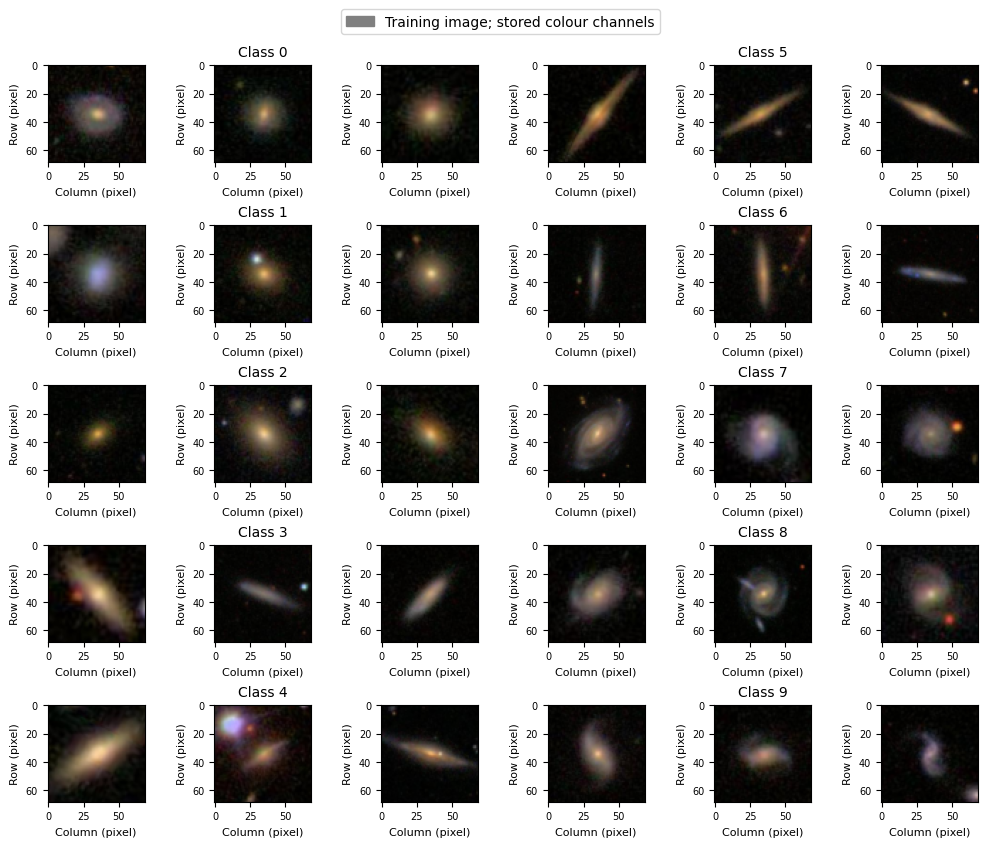

In [2]:
# PART 2.1: Load the galaxy images, split the data, and inspect each class

data_path = DATA_DIR / "Galaxy10.h5"
data_url = "https://zenodo.org/records/10844811/files/Galaxy10.h5?download=1"
if not data_path.exists():
    urlretrieve(data_url, data_path)

with h5py.File(data_path, "r") as f:
    images = f["images"][:]
    labels = f["ans"][:].astype(np.int64)

all_idx = np.arange(len(labels))
train_idx, rest_idx = train_test_split(
    all_idx, test_size=0.30, stratify=labels, random_state=SPLIT_SEED
)
val_idx, test_idx = train_test_split(
    rest_idx, test_size=0.50, stratify=labels[rest_idx], random_state=SPLIT_SEED
)

counts = pd.DataFrame({
    "class": CLASS_NAMES,
    "all": np.bincount(labels, minlength=10),
    "train": np.bincount(labels[train_idx], minlength=10),
    "validation": np.bincount(labels[val_idx], minlength=10),
    "test": np.bincount(labels[test_idx], minlength=10)
})
print("Images:", images.shape, images.dtype, "range:", (images.min(), images.max()))
print("Labels:", labels.shape, labels.dtype)
print("Split sizes:", len(train_idx), len(val_idx), len(test_idx))
display(counts)

rng = np.random.default_rng(SPLIT_SEED)
example_idx = [rng.choice(train_idx[labels[train_idx] == c], 3, replace=False) for c in range(10)]
fig, axes = plt.subplots(5, 6, figsize=(10, 8), constrained_layout=True)
for c in range(10):
    for j in range(3):
        ax = axes[c % 5, 3 * (c // 5) + j]
        ax.imshow(images[example_idx[c][j]])
        ax.set_title(f"Class {c}" if j == 1 else "", fontsize=10)
        ax.set_xlabel("Column (pixel)", fontsize=8)
        ax.set_ylabel("Row (pixel)", fontsize=8)
        ax.tick_params(labelsize=7)
fig.legend(handles=[Patch(color="gray", label="Training image; stored colour channels")],
           loc="lower center", bbox_to_anchor=(0.5, 1.0))
plt.show()


### 2.2(a). Sky noise

For each training image and band, I used the outer four-pixel frame (1,040 pixels) to find the median sky, standard deviation, and

$$\sigma_{\rm MAD}=1.4826\,\operatorname{median}(|I-\operatorname{median}(I)|).$$

| Band | Median sky | Median standard deviation | Median MAD noise |
|---|---:|---:|---:|
| g | 6 | 5.99 | 4.45 |
| r | 6 | 5.21 | 2.97 |
| i | 3 | 4.51 | 2.97 |

Neighbors and galaxy outskirts raise the standard deviation more than the MAD. The middle-band sky's 5th–95th percentile range is 3–12, so one sky value wouldn't suit every image.


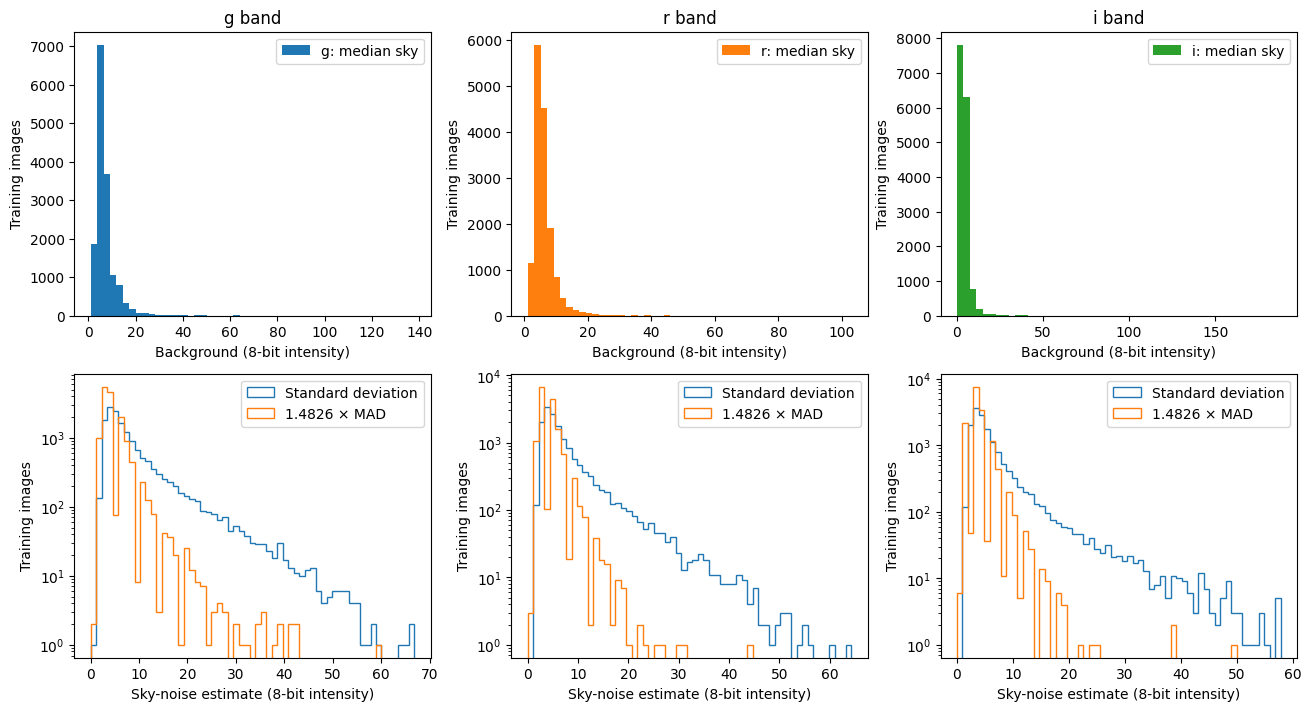

,band,median background,background p05,background p95,median sigma_std,median sigma_MAD,zero MAD fraction
0,g,6.0,3.0,15.0,5.989668,4.4478,0.000131
1,r,6.0,3.0,12.0,5.213939,2.9652,0.000197
2,i,3.0,2.0,9.0,4.508852,2.9652,0.000328


In [3]:
# PART 2.2(a): Estimate the sky level and noise in each color band

border_mask = np.ones((69, 69), dtype=bool)
border_mask[4:-4, 4:-4] = False

# Estimate each image and band separately from the border pixels.
def estimate_sky(raw):
    border = raw[:, border_mask, :].astype(np.float32)
    background = np.median(border, axis=1)
    sigma_std = border.std(axis=1)
    sigma_mad = 1.4826 * np.median(np.abs(border - background[:, None, :]), axis=1)
    return background, sigma_std, sigma_mad

train_sky = np.empty((len(train_idx), 3), dtype=np.float32)
train_std = np.empty_like(train_sky)
train_mad = np.empty_like(train_sky)
for start in range(0, len(train_idx), 256):
    sl = slice(start, start + 256)
    train_sky[sl], train_std[sl], train_mad[sl] = estimate_sky(images[train_idx[sl]])

fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
for band, name in enumerate(BANDS):
    axes[0, band].hist(train_sky[:, band], bins=50, color=f"C{band}", label=f"{name}: median sky")
    axes[0, band].set(xlabel="Background (8-bit intensity)", ylabel="Training images", title=f"{name} band")
    upper = max(train_std[:, band].max(), train_mad[:, band].max())
    bins = np.linspace(0, upper + 0.01, 60)
    axes[1, band].hist(train_std[:, band], bins=bins, histtype="step", label="Standard deviation")
    axes[1, band].hist(train_mad[:, band], bins=bins, histtype="step", label="1.4826 × MAD")
    axes[1, band].set(xlabel="Sky-noise estimate (8-bit intensity)", ylabel="Training images", yscale="log")
    axes[0, band].legend()
    axes[1, band].legend()
plt.show()

sky_summary = pd.DataFrame({
    "band": BANDS, "median background": np.median(train_sky, axis=0),
    "background p05": np.percentile(train_sky, 5, axis=0),
    "background p95": np.percentile(train_sky, 95, axis=0),
    "median sigma_std": np.median(train_std, axis=0),
    "median sigma_MAD": np.median(train_mad, axis=0),
    "zero MAD fraction": (train_mad == 0).mean(axis=0)
})
display(sky_summary)


### 2.2(b). Signal-to-noise ratio

I used the middle band and a radius-8 aperture centered at $(34,34)$, containing 197 pixels:

$$\mathrm{S/N}=\frac{\sum_{p\in A}(I_{p,r}-b_r)}{\sigma_{{\rm sky},r}\sqrt{197}}.$$

Some MADs are zero, so I set a minimum noise of $1/\sqrt{12}$, the one-count rounding noise. Class 6 has the lowest median S/N (**363.5**) and flux (**12,348**); class 7 has the highest median S/N (**532.0**). Class 6 looks fainter here, though distance and size also matter. This estimate omits shot noise and pixel correlations.


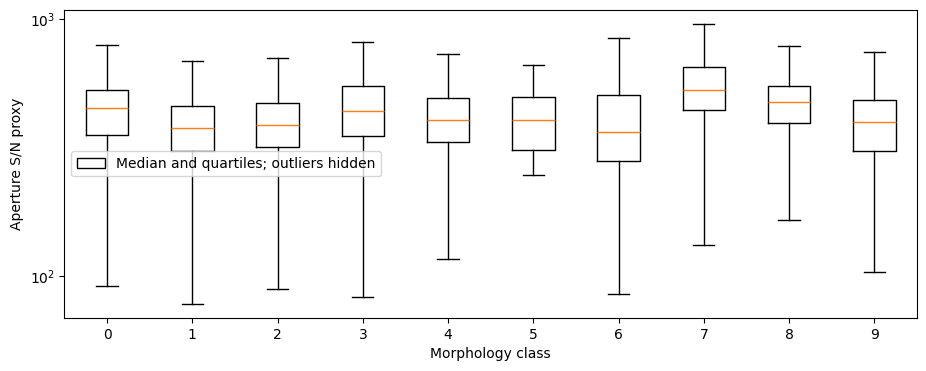

,class,median S/N (MAD),median aperture flux
0,"Face-on, no spiral",453.067044,20775.0
1,"Smooth, round",376.931169,22210.5
2,"Smooth, intermediate",387.207022,24047.5
3,"Smooth, cigar",440.044009,21449.5
4,"Edge-on, rounded bulge",406.525325,19364.5
5,"Edge-on, boxy bulge",403.954346,16812.0
6,"Edge-on, no bulge",363.527675,12348.0
7,Tight spiral,531.974138,21368.0
8,Medium spiral,474.523815,20054.5
9,Loose spiral,396.746024,18721.0


Aperture pixels: 197 ; fraction using noise floor: 0.0001967342120794806


In [4]:
# PART 2.2(b): Compare signal-to-noise ratios across the classes

yy, xx = np.indices((69, 69))
radius = np.sqrt((yy - 34)**2 + (xx - 34)**2)
aperture = radius <= 8
n_aperture = int(aperture.sum())
flux = np.empty(len(train_idx))
for start in range(0, len(train_idx), 256):
    sl = slice(start, start + 256)
    flux[sl] = images[train_idx[sl]][:, aperture, 1].sum(axis=1) - n_aperture * train_sky[sl, 1]
noise_floor = 1 / np.sqrt(12)
snr_mad = flux / (np.maximum(train_mad[:, 1], noise_floor) * np.sqrt(n_aperture))
fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot([snr_mad[labels[train_idx] == c] for c in range(10)], tick_labels=range(10), showfliers=False)
ax.set(xlabel="Morphology class", ylabel="Aperture S/N proxy", yscale="symlog")
ax.legend(handles=[Patch(facecolor="white", edgecolor="black", label="Median and quartiles; outliers hidden")])
plt.show()
snr_summary = pd.DataFrame({
    "class": CLASS_NAMES,
    "median S/N (MAD)": [np.median(snr_mad[labels[train_idx] == c]) for c in range(10)],
    "median aperture flux": [np.median(flux[labels[train_idx] == c]) for c in range(10)]
})
display(snr_summary)
print("Aperture pixels:", n_aperture, "; fraction using noise floor:", (train_mad[:, 1] < noise_floor).mean())


### 2.2(c). Contamination and clipping

I flagged three or more touching border pixels above $b_r+5\max(\sigma_{{\rm MAD},r},1)$, including diagonals. **61.70%** of images pass; outskirts and noise can also trigger this. **0.001758%** of spatial pixels have a channel at 255. Neighbors bias the sky, while clipping and rounding erase brightness differences. Clipping in these files doesn't necessarily mean detector saturation.


Flagged border sources: 0.6170240671519444
Fraction of spatial pixels with any channel at 255: 1.757563919438614e-05


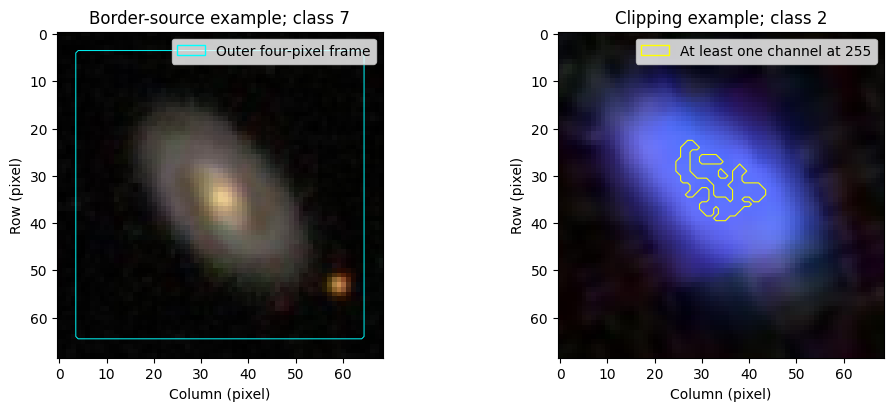

In [5]:
# PART 2.2(c): Check for bright border sources and clipped pixels

contaminated = np.zeros(len(train_idx), dtype=bool)
saturated_pixel_counts = np.zeros(len(train_idx), dtype=np.int64)
for j, image_idx in enumerate(train_idx):
    raw = images[image_idx]
    bright = border_mask & (raw[:, :, 1] > train_sky[j, 1] + 5 * max(train_mad[j, 1], 1.0))
    components, number = ndimage.label(bright, structure=np.ones((3, 3)))
    sizes = np.bincount(components.ravel())[1:]
    contaminated[j] = bool(len(sizes) and sizes.max() >= 3)
    saturated_pixel_counts[j] = np.count_nonzero(np.any(raw == 255, axis=-1))

print("Flagged border sources:", contaminated.mean())
print("Fraction of spatial pixels with any channel at 255:", saturated_pixel_counts.sum() / (len(train_idx) * 69 * 69))

candidate_border = np.flatnonzero(contaminated)
candidate_clip = np.flatnonzero(saturated_pixel_counts > 0)
chosen = [candidate_border[0] if len(candidate_border) else 0,
          candidate_clip[np.argmax(saturated_pixel_counts[candidate_clip])] if len(candidate_clip) else 0]
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for ax, j, title in zip(axes, chosen, ["Border-source example", "Clipping example"]):
    ax.imshow(images[train_idx[j]])
    ax.set(xlabel="Column (pixel)", ylabel="Row (pixel)", title=f"{title}; class {labels[train_idx[j]]}")
axes[0].contour(border_mask, levels=[0.5], colors=["cyan"], linewidths=0.7)
axes[0].legend(handles=[Patch(facecolor="none", edgecolor="cyan", label="Outer four-pixel frame")])
clip_mask = np.any(images[train_idx[chosen[1]]] == 255, axis=-1)
if clip_mask.any() and not clip_mask.all():
    axes[1].contour(clip_mask, levels=[0.5], colors=["yellow"], linewidths=0.8)
axes[1].legend(handles=[Patch(facecolor="none", edgecolor="yellow", label="At least one channel at 255")])
plt.show()


### 2.2(d). Label noise

I expect confusion between 1/2, 2/3, 4/5/6, and 7/8/9, plus class 0 and smooth galaxies when arms are faint. Volunteers can disagree, so even a sensible prediction can fail against the test label. We would need vote information to estimate an accuracy ceiling.

Cropping, sky subtraction, and averaging can help with unwanted light and noise. They can't restore clipped detail or fix uncertain labels.


### 2.3(a). Crop

The average sky-subtracted training image has most of its light near the center. Using one-pixel radial bins, the **48 by 48** crop (`10:58`) keeps **91.15%, 91.29%, 90.62%** of positive stacked light in g/r/i. I accepted losing some outskirts to remove border sky and contamination. Large or off-center galaxies can lose more.


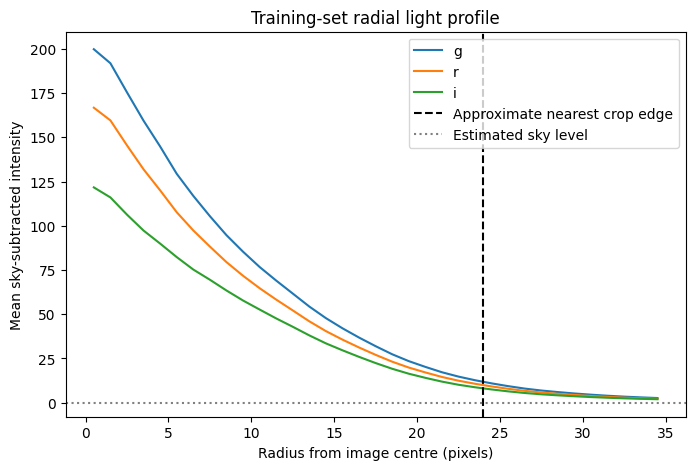

Retained positive stacked light, g/r/i: [0.91151015 0.91285914 0.90616952]


In [6]:
# PART 2.3(a): Measure the radial profile and check the 48 x 48 crop

stack_sum = np.zeros((69, 69, 3), dtype=np.float64)
for start in range(0, len(train_idx), 256):
    sl = slice(start, start + 256)
    corrected = images[train_idx[sl]].astype(np.float32) - train_sky[sl, None, None, :]
    stack_sum += corrected.sum(axis=0, dtype=np.float64)
stack = stack_sum / len(train_idx)
radial_bin = np.floor(radius).astype(int)
radial_profile = np.array([stack[radial_bin == r].mean(axis=0) for r in range(35)])
positive_stack = np.maximum(stack, 0)
crop_fraction = positive_stack[10:58, 10:58].sum(axis=(0, 1)) / positive_stack.sum(axis=(0, 1))

fig, ax = plt.subplots(figsize=(8, 5))
for band, name in enumerate(BANDS):
    ax.plot(np.arange(35) + 0.5, radial_profile[:, band], label=name)
ax.axvline(24, color="black", linestyle="--", label="Approximate nearest crop edge")
ax.axhline(0, color="gray", linestyle=":", label="Estimated sky level")
ax.set(xlabel="Radius from image centre (pixels)", ylabel="Mean sky-subtracted intensity", title="Training-set radial light profile")
ax.legend()
plt.show()
print("Retained positive stacked light, g/r/i:", crop_fraction)


### 2.3(b). Normalization

After converting to float32 and subtracting the sky, I used

$$z_{p,c}=\frac{I_{p,c}-b_c-\mu_c}{s_c}.$$

Training means are **(38.8693, 32.6744, 26.2158)** and standard deviations **(44.5335, 37.3249, 31.6007)**. After preprocessing, means are within $2\times10^{-8}$ of zero and standard deviations are **1.0000**. I reuse the training values for validation and test to avoid data leakage.

Dividing by each image's brightest pixel removes overall brightness and is sensitive to neighbors. Doing it separately per band also removes color. I kept a shared scale because brightness tells us how visible the galaxy is.


In [7]:
# PART 2.3(b): Prepare the images and normalize using training statistics

# Return tensors in PyTorch order: images, channels, height, width.
def prepare_images(indices, offsets=None):
    output = np.empty((len(indices), 3, 48, 48), dtype=np.float32)
    for start in range(0, len(indices), 256):
        batch = images[indices[start:start + 256]]
        sky = np.median(batch[:, border_mask, :], axis=1).astype(np.float32)
        if offsets is None:
            cropped = batch[:, 10:58, 10:58].astype(np.float32)
        else:
            cropped = np.empty((len(batch), 48, 48, 3), dtype=np.float32)
            for j, (dy, dx) in enumerate(offsets[start:start + 256]):
                cropped[j] = batch[j, 10 + dy:58 + dy, 10 + dx:58 + dx]
        output[start:start + 256] = (cropped - sky[:, None, None, :]).transpose(0, 3, 1, 2)
    return torch.from_numpy(output)

x_train = prepare_images(train_idx)
# Fit normalization on training images only.
band_mean = x_train.numpy().mean(axis=(0, 2, 3), dtype=np.float64)
band_std = x_train.numpy().std(axis=(0, 2, 3), dtype=np.float64)

def standardise(x):
    mean = torch.tensor(band_mean, dtype=torch.float32)[None, :, None, None]
    std = torch.tensor(band_std, dtype=torch.float32)[None, :, None, None]
    return (x - mean) / std

x_train = standardise(x_train)
x_val = standardise(prepare_images(val_idx))
y_train = torch.from_numpy(labels[train_idx])
y_val = torch.from_numpy(labels[val_idx])
display(pd.DataFrame({"band": BANDS, "fitted mean": band_mean, "fitted std": band_std,
                      "processed mean": x_train.mean(dim=(0, 2, 3)).numpy(),
                      "processed std": x_train.std(dim=(0, 2, 3), correction=0).numpy()}))


,band,fitted mean,fitted std,processed mean,processed std
0,g,38.869290,44.533542,3.887911e-09,1.0
1,r,32.674449,37.324927,-1.862653e-08,1.0
2,i,26.215757,31.600732,-1.716900e-08,1.0


### 2.3(c). Background subtraction

I subtracted each band's frame median because sky levels vary. Bright pixels affect it less than the mean, though a large galaxy can still bias it high. I used no smoothing or sharpening. The processed examples use a color scale for the middle band because values can be negative.


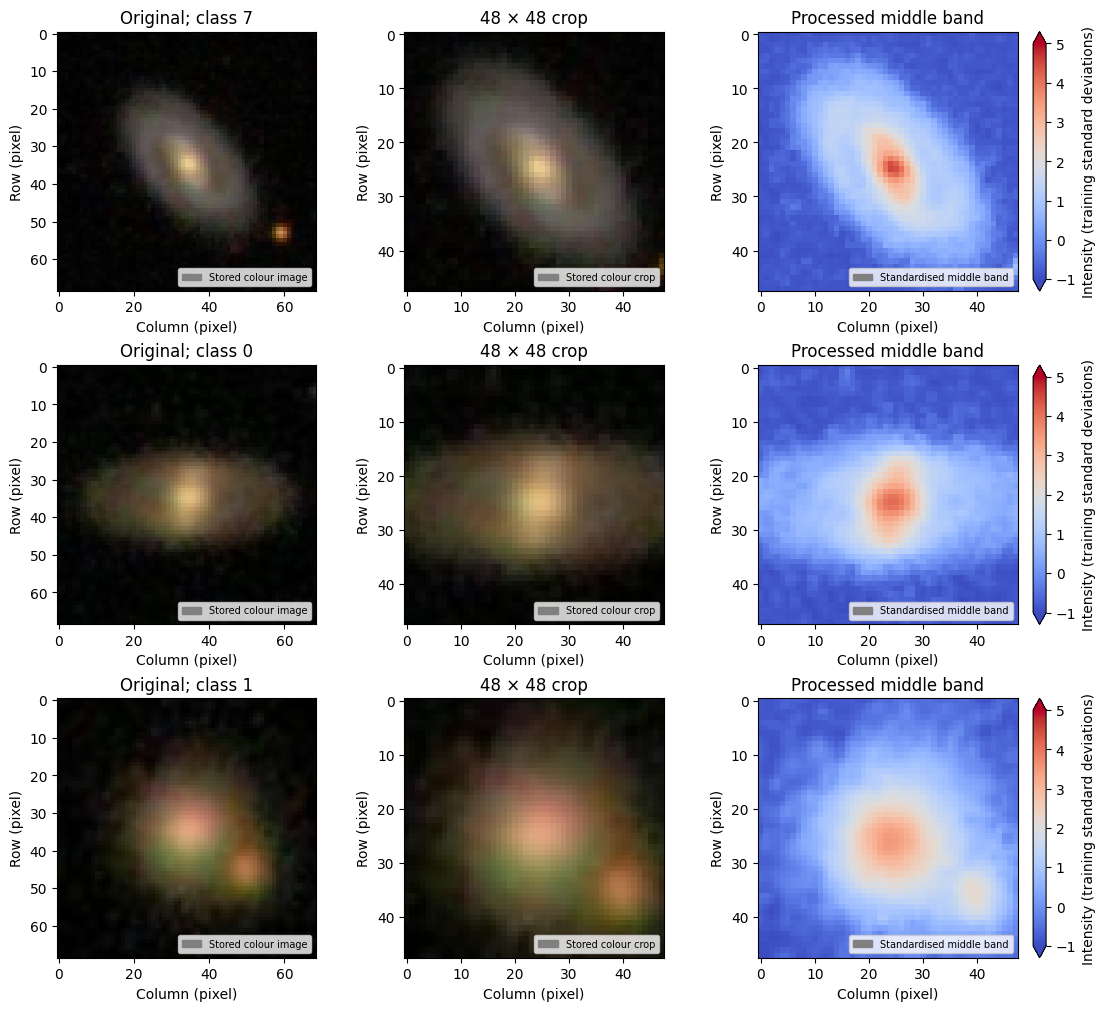

In [9]:
# PART 2.3(c): Compare the original images with the processed inputs

fig, axes = plt.subplots(3, 3, figsize=(11, 10), constrained_layout=True)
for row, j in enumerate([0, 100, 200]):
    image_idx = train_idx[j]
    axes[row, 0].imshow(images[image_idx])
    axes[row, 0].set_title(f"Original; class {labels[image_idx]}")
    axes[row, 1].imshow(images[image_idx, 10:58, 10:58])
    axes[row, 1].set_title("48 × 48 crop")
    plot = axes[row, 2].imshow(x_train[j, 1], cmap="coolwarm", vmin=-1, vmax=5)
    axes[row, 2].set_title("Processed middle band")
    fig.colorbar(plot, ax=axes[row, 2], label="Intensity (training standard deviations)", extend="both")
    for col, label in enumerate(["Stored colour image", "Stored colour crop", "Standardised middle band"]):
        axes[row, col].set(xlabel="Column (pixel)", ylabel="Row (pixel)")
        axes[row, col].legend(handles=[Patch(color="gray", label=label)], fontsize=7, loc="lower right")
plt.show()


### 2.3(d). Class imbalance

I used class-weighted cross-entropy, $w_c=N_{\rm train}/(10n_c)$, and shuffled batches. Plain accuracy favors common classes, so I also report **balanced accuracy**, the average class recall. Weighting gives rare classes more say, but class 5 still has only two test examples.


In [10]:
# PART 2.3(d): Give rare classes more weight in the loss

train_counts = np.bincount(labels[train_idx], minlength=10)
class_weights = torch.tensor(len(train_idx) / (10 * train_counts), dtype=torch.float32)
display(pd.DataFrame({"class": CLASS_NAMES, "training count": train_counts, "loss weight": class_weights.numpy()}))


,class,training count,loss weight
0,"Face-on, no spiral",2423,0.629344
1,"Smooth, round",4898,0.311331
2,"Smooth, intermediate",4404,0.346253
3,"Smooth, cigar",244,6.249590
4,"Edge-on, rounded bulge",1074,1.419832
5,"Edge-on, boxy bulge",12,127.074997
6,"Edge-on, no bulge",412,3.701214
7,Tight spiral,785,1.942548
8,Medium spiral,634,2.405205
9,Loose spiral,363,4.200827


### 2.4. Augmentation

| Transformation | Use it? | Reason |
|---|---|---|
| Arbitrary rotation | Carefully | Same label, but interpolation/cropping can lose detail. |
| $90^\circ$ rotations | Yes | Same label, no interpolation. |
| Horizontal/vertical flips | Yes | Labels don't distinguish spiral handedness. |
| Small shifts | Yes | Position isn't morphology, unless the crop cuts it off. |
| Zoom | Small amounts | Changes apparent size and visible detail. |
| Relative band intensity | No random changes | Color reflects stars, dust, and redshift. |
| Blur | For known seeing | Can erase arms and bulges. |

I would start with flips and right-angle rotations. The required baseline uses **no augmentation**.


## Part 3 - FCNN and CNN comparison


### Training settings

All models use the same data, preprocessing, weighted loss, Adam (**0.001**), batch size **128**, and at most **50 epochs**. Early stopping waits **5** epochs without lower validation loss, then restores the best weights. Baseline seeds are **11, 22, 33**; scrambled runs use **11**. No augmentation or added weight decay.

I timed training and validation on an **Intel Core i7-13700H CPU**, using four threads and PyTorch 2.14.1+cpu. Preprocessing and saving are excluded. The code synchronizes CUDA if a GPU is used.


### 3.1. Model definitions

In [11]:
# PART 3.1: Define the three networks and check their parameter counts

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 6 * 6, 64), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

class FCNN(nn.Module):
    def __init__(self, first_width, second_width):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(), nn.Linear(3 * 48 * 48, first_width), nn.ReLU(),
            nn.Linear(first_width, second_width), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(second_width, 10)
        )

    def forward(self, x):
        return self.layers(x)

def make_model(name):
    if name == "CNN":
        return CNN()
    widths = {"FCNN-matched": (24, 64), "FCNN-large": (256, 128)}
    return FCNN(*widths[name])

MODEL_NAMES = ["FCNN-matched", "FCNN-large", "CNN"]
PARAMETERS = {"FCNN-matched": 168162, "FCNN-large": 1803914, "CNN": 171754}
MACS = {"FCNN-matched": 168064, "FCNN-large": 1803520, "CNN": 6451840}
for name in MODEL_NAMES:
    model = make_model(name)
    count = sum(p.numel() for p in model.parameters())
    print(f"{name}: {count:,} parameters (matches T1)")


FCNN-matched: 168,162 parameters (matches T1)
FCNN-large: 1,803,914 parameters (matches T1)
CNN: 171,754 parameters (matches T1)


### 3.1. Training

`RETRAIN = False` loads saved runs and their original timings. Set it to `True`
for fresh training or after changing the models or preprocessing.


In [12]:
# PART 3.1: Use the same training and early-stopping rules for every model

# Wait for GPU work before reading the clock.
def clock_time():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    return time.perf_counter()

def make_loader(x, y, shuffle=False, seed=0):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(TensorDataset(x, y), batch_size=128, shuffle=shuffle,
                      generator=generator)

def run_epoch(model, loader, loss_function, optimiser=None):
    training = optimiser is not None
    model.train(training)
    weighted_loss, weight_total, correct, total = 0.0, 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if training:
                optimiser.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = loss_function(logits, yb)
            if training:
                loss.backward()
                optimiser.step()
            # Combine batch losses using the sum of class weights.
            batch_weight = loss_function.weight[yb].sum().item()
            weighted_loss += loss.item() * batch_weight
            weight_total += batch_weight
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += len(yb)
    return weighted_loss / weight_total, correct / total

# Set True to retrain, including after changing the data or architecture.
RETRAIN = False

def train_model(name, seed, training_images, validation_images, experiment="baseline"):
    run_name = f"{experiment}_{name}_{seed}"
    checkpoint = RESULTS_DIR / f"{run_name}.pt"
    history_path = RESULTS_DIR / f"{run_name}.csv"
    if not RETRAIN and checkpoint.exists() and history_path.exists():
        history = pd.read_csv(history_path)
        print("Loaded:", run_name)
    else:
        torch.manual_seed(seed)
        model = make_model(name).to(DEVICE)
        optimiser = torch.optim.Adam(model.parameters(), lr=0.001)
        loss_function = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE))
        train_loader = make_loader(training_images, y_train, shuffle=True, seed=seed)
        val_loader = make_loader(validation_images, y_val)
        best_loss, bad_epochs, elapsed = float("inf"), 0, 0.0
        history = []
        for epoch in range(1, 51):
            start = clock_time()
            train_loss, train_acc = run_epoch(model, train_loader, loss_function, optimiser)
            val_loss, val_acc = run_epoch(model, val_loader, loss_function)
            seconds = clock_time() - start
            elapsed += seconds
            history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                            "train_accuracy": train_acc, "val_accuracy": val_acc,
                            "epoch_seconds": seconds, "elapsed_seconds": elapsed})
            if val_loss < best_loss:
                best_loss, bad_epochs = val_loss, 0
                # Clone the best weights so later updates cannot change them.
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            else:
                bad_epochs += 1
            print(f"{run_name}, epoch {epoch}: validation loss {val_loss:.4f}")
            if bad_epochs == 5:
                break
        model.load_state_dict(best_state)
        torch.save(model.state_dict(), checkpoint)
        history = pd.DataFrame(history)
        history.to_csv(history_path, index=False)
    best = history.loc[history.val_loss.idxmin()]
    return {"name": name, "seed": seed, "checkpoint": checkpoint, "history": history,
            "best_epoch": int(best.epoch), "best_val_loss": best.val_loss}

def load_model(run):
    model = make_model(run["name"]).to(DEVICE)
    model.load_state_dict(torch.load(run["checkpoint"], map_location=DEVICE, weights_only=True))
    model.eval()
    return model

@torch.no_grad()
def predict(model, x):
    probabilities = []
    model.eval()
    for start in range(0, len(x), 128):
        logits = model(x[start:start + 128].to(DEVICE))
        probabilities.append(torch.softmax(logits, dim=1).cpu().numpy())
    return np.concatenate(probabilities)


In [14]:
# PART 3.1: Train each model with three random seeds

baseline_runs = []
for name in MODEL_NAMES:
    for seed in SEEDS:
        baseline_runs.append(train_model(name, seed, x_train, x_val))


Loaded: baseline_FCNN-matched_11
Loaded: baseline_FCNN-matched_22
Loaded: baseline_FCNN-matched_33
Loaded: baseline_FCNN-large_11
Loaded: baseline_FCNN-large_22
Loaded: baseline_FCNN-large_33
Loaded: baseline_CNN_11
Loaded: baseline_CNN_22
Loaded: baseline_CNN_33


### 3.3. Training on scrambled images

I trained these before evaluating the test set. One fixed permutation (seed
2026) is shared by every image and all three channels. Both runs use seed 11.


In [15]:
# PART 3.3: Train the scrambled models before evaluating the test set

permutation = np.random.default_rng(2026).permutation(48 * 48)

# Keep each pixel's three channels together.
def scramble(x):
    return x.flatten(start_dim=2)[:, :, permutation].reshape_as(x)

x_train_scrambled = scramble(x_train)
x_val_scrambled = scramble(x_val)
scrambled_runs = [train_model(name, 11, x_train_scrambled, x_val_scrambled, "scrambled")
                  for name in ["FCNN-matched", "CNN"]]
del x_train_scrambled, x_val_scrambled


Loaded: scrambled_FCNN-matched_11
Loaded: scrambled_CNN_11


### 3.1. Baseline results

The target is FCNN-matched's best validation accuracy, **61.41%**. The main scores and times are in Part 4(a).

| Model | Target reached | Epochs to target | Selected epoch |
|---|---:|---:|---:|
| FCNN-matched | 1/3 | 13.00 (one run) | 8.67 ± 1.53 |
| FCNN-large | 2/3 | 6.50 ± 2.12 | 3.33 ± 0.58 |
| CNN | 3/3 | 12.67 ± 2.52 | 12.33 ± 0.58 |

Values are mean ± sample standard deviation. Target times and epochs count only successful runs and use the first crossing. One successful run has no across-seed deviation. Selected epochs have the lowest validation loss. The code's parameter counts agree with T1.


In [16]:
# PART 3.1: Compare test performance and training time

x_test = standardise(prepare_images(test_idx))
y_test = labels[test_idx]
target_accuracy = max(run["history"]["val_accuracy"].max() for run in baseline_runs
                      if run["name"] == "FCNN-matched")
baseline_probabilities = {}
baseline_rows = []
for run in baseline_runs:
    probabilities = predict(load_model(run), x_test)
    baseline_probabilities[(run["name"], run["seed"])] = probabilities
    predicted = probabilities.argmax(axis=1)
    history = run["history"]
    # A run that misses the target stays NaN, not zero seconds.
    reached = history[history.val_accuracy >= target_accuracy]
    first = None if reached.empty else reached.iloc[0]
    baseline_rows.append({
        "model": run["name"], "seed": run["seed"],
        "accuracy": accuracy_score(y_test, predicted),
        "balanced_accuracy": balanced_accuracy_score(y_test, predicted),
        "parameters": PARAMETERS[run["name"]], "MACs": MACS[run["name"]],
        "seconds_per_epoch": history.epoch_seconds.mean(),
        "epochs_to_target": np.nan if first is None else first.epoch,
        "seconds_to_target": np.nan if first is None else first.elapsed_seconds,
        "reached_target": first is not None, "selected_epoch": run["best_epoch"]
    })
baseline_results = pd.DataFrame(baseline_rows)
columns = ["accuracy", "balanced_accuracy", "parameters", "MACs", "seconds_per_epoch",
           "epochs_to_target", "seconds_to_target", "selected_epoch"]
grouped = baseline_results.groupby("model", sort=False)
baseline_summary = grouped[columns].agg(["mean", "std"])
baseline_summary[("reached_target", "count")] = grouped.reached_target.sum()
print(f"Common target validation accuracy: {100 * target_accuracy:.2f}%")
display(baseline_summary.round(3))


Common target validation accuracy: 61.41%


accuracy        balanced_accuracy        parameters       \
                 mean    std              mean    std       mean  std   
model                                                                   
FCNN-matched    0.505  0.062             0.447  0.023   168162.0  0.0   
FCNN-large      0.519  0.036             0.447  0.005  1803914.0  0.0   
CNN             0.579  0.090             0.520  0.043   171754.0  0.0   

                   MACs      seconds_per_epoch        epochs_to_target         \
                   mean  std              mean    std             mean    std   
model                                                                           
FCNN-matched   168064.0  0.0             1.605  0.490           13.000    NaN   
FCNN-large    1803520.0  0.0             2.595  0.360            6.500  2.121   
CNN           6451840.0  0.0            36.264  0.673           12.667  2.517   

             seconds_to_target          selected_epoch        reached_target  
                          mean      std           mean    std          count  
model                                                                         
FCNN-matched            27.961      NaN          8.667  1.528              1  
FCNN-large              15.557    5.139          3.333  0.577              2  
CNN                    466.315  100.685         12.333  0.577              3

### 3.1. Loss curves

For CNN seed 11, training loss falls **1.024→0.820** over epochs 12–17 while validation loss rises **1.342→1.468**: it overfits too. I kept epoch 12. Each of the three class-5 validation images has weight about **127**, making validation noisy. Dropout is on only during training.


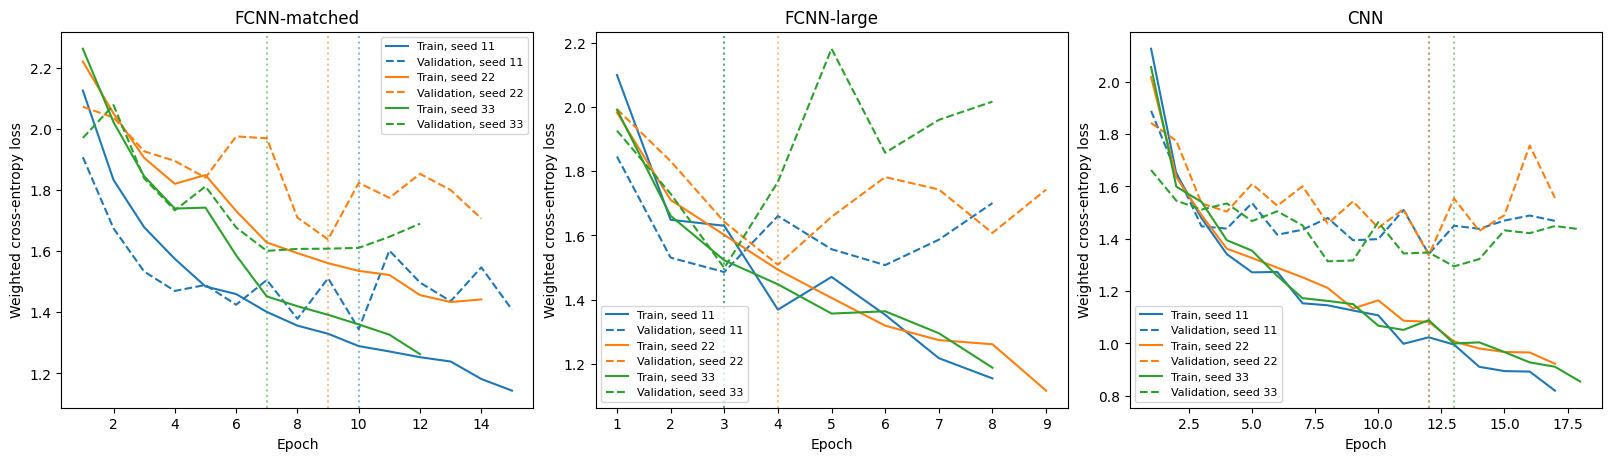

In [18]:
# PART 3.1: Plot training and validation loss

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
for ax, name in zip(axes, MODEL_NAMES):
    for j, seed in enumerate(SEEDS):
        run = next(r for r in baseline_runs if r["name"] == name and r["seed"] == seed)
        h = run["history"]
        ax.plot(h.epoch, h.train_loss, color=f"C{j}", label=f"Train, seed {seed}")
        ax.plot(h.epoch, h.val_loss, "--", color=f"C{j}", label=f"Validation, seed {seed}")
        ax.axvline(run["best_epoch"], color=f"C{j}", linestyle=":", alpha=0.5)
    ax.set(xlabel="Epoch", ylabel="Weighted cross-entropy loss", title=name)
    ax.legend(fontsize=8)
plt.show()


### 3.1. Confusion matrices

The best seeds by validation loss are **11, 11, 33** for matched, large, and CNN. Their most common mistake is **class 2 as class 1**: **297, 331, 113** images. The CNN swaps 41 tight and 35 medium spirals into each other's classes. These match the expected overlaps. It also misses both class-5 images and gets only **20.6%** of class 0 right.


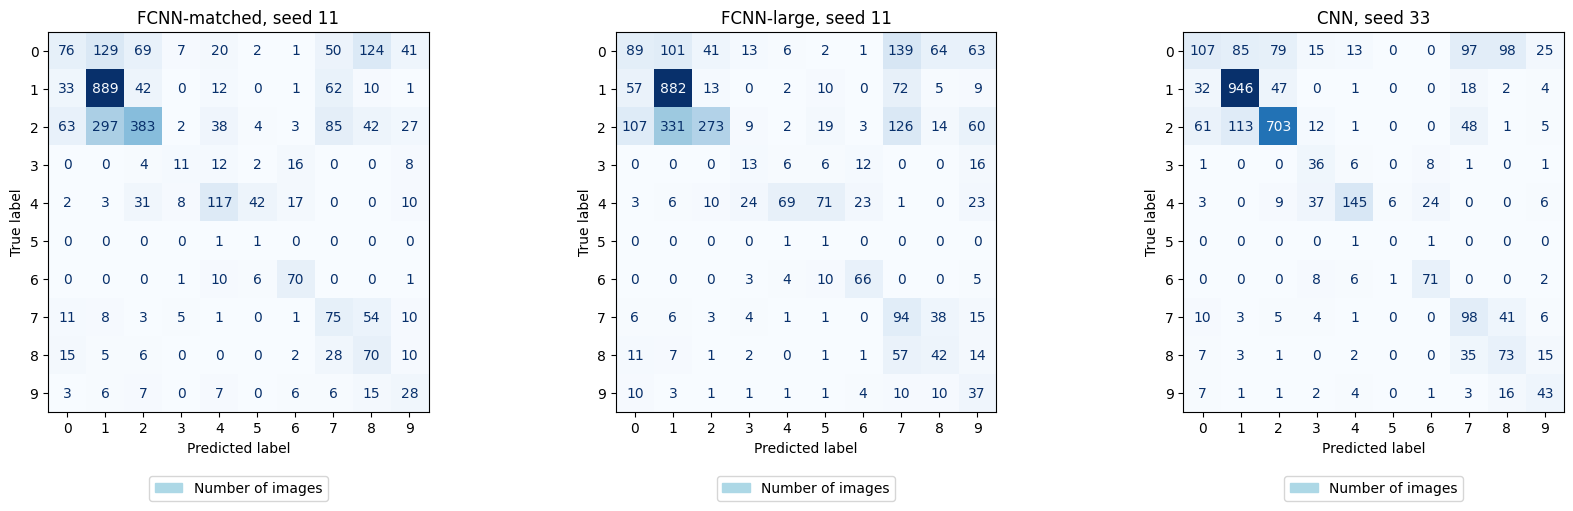

,FCNN-matched,FCNN-large,CNN
"Face-on, no spiral",0.146,0.171,0.206
"Smooth, round",0.847,0.840,0.901
"Smooth, intermediate",0.406,0.289,0.745
"Smooth, cigar",0.208,0.245,0.679
"Edge-on, rounded bulge",0.509,0.300,0.630
"Edge-on, boxy bulge",0.500,0.500,0.000
"Edge-on, no bulge",0.795,0.750,0.807
Tight spiral,0.446,0.560,0.583
Medium spiral,0.515,0.309,0.537
Loose spiral,0.359,0.474,0.551


In [19]:
# PART 3.1: Show the confusion matrix of each model's best seed

# Choose seeds by validation loss.
best_runs = {name: min((r for r in baseline_runs if r["name"] == name),
                       key=lambda r: r["best_val_loss"]) for name in MODEL_NAMES}
fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
class_recalls = {}
for ax, name in zip(axes, MODEL_NAMES):
    run = best_runs[name]
    predicted = baseline_probabilities[(name, run["seed"])].argmax(axis=1)
    cm = confusion_matrix(y_test, predicted, labels=range(10))
    class_recalls[name] = np.diag(cm) / cm.sum(axis=1)
    ConfusionMatrixDisplay(cm).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name}, seed {run['seed']}")
    ax.legend(handles=[Patch(color="lightblue", label="Number of images")],
              loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.show()
display(pd.DataFrame(class_recalls, index=CLASS_NAMES).round(3))


### 3.1. ROC curves

Using softmax scores, class-2/class-7 AUCs are **0.780/0.889** (matched), **0.778/0.877** (large), and **0.912/0.929** (CNN). The CNN ranks these classes best; AUC isn't the same as ten-class accuracy.


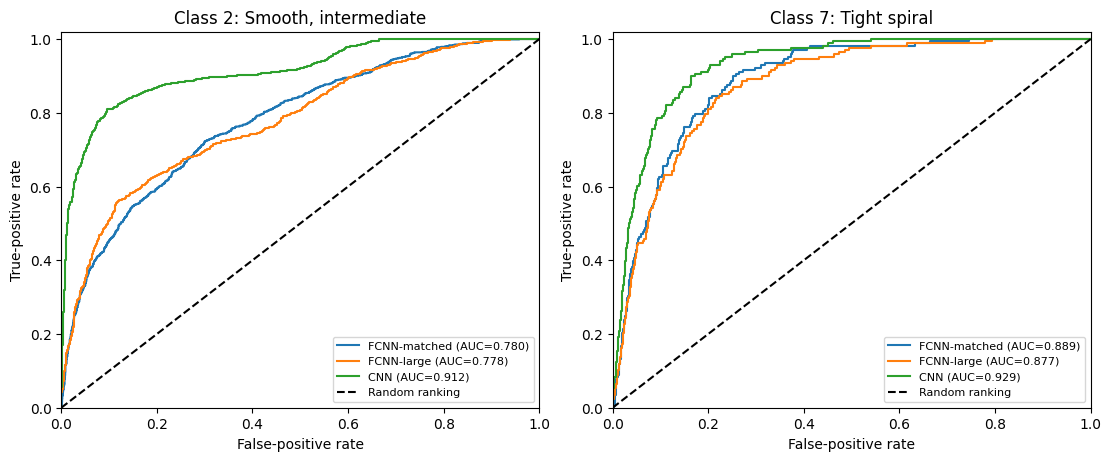

In [20]:
# PART 3.1: Plot one-versus-rest ROC curves for two classes

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
for ax, class_id in zip(axes, [2, 7]):
    for name in MODEL_NAMES:
        run = best_runs[name]
        probabilities = baseline_probabilities[(name, run["seed"])]
        fpr, tpr, _ = roc_curve(y_test == class_id, probabilities[:, class_id])
        score = auc(fpr, tpr)
        ax.plot(fpr, tpr, label=f"{name} (AUC={score:.3f})")
    ax.plot([0, 1], [0, 1], "k--", label="Random ranking")
    ax.set(xlabel="False-positive rate", ylabel="True-positive rate",
           title=f"Class {class_id}: {CLASS_NAMES[class_id]}", xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(fontsize=8)
plt.show()


### 3.2. Shifted images

I shifted each crop by $d=0,2,4,6,8$ in a random direction (seed **3200**), rounded to pixels. All models use the same shifts, original sky estimates, normalization, and weights.

| Model | Accuracy at $d=8$ (%) | Drop from $d=0$ (points) |
|---|---:|---:|
| FCNN-matched | 20.25 ± 3.64 | 30.28 |
| FCNN-large | 17.25 ± 3.74 | 34.70 |
| CNN | 30.79 ± 4.85 | 27.15 |

The CNN loses less, as predicted, but isn't invariant. Pooling boundaries, position-specific dense weights, and cut-off light still matter. Rounding slightly changes the distances from $d$.


,mean_actual_distance
displacement,
0,0.000000
2,2.091816
4,4.059657
6,6.037507
8,8.049493


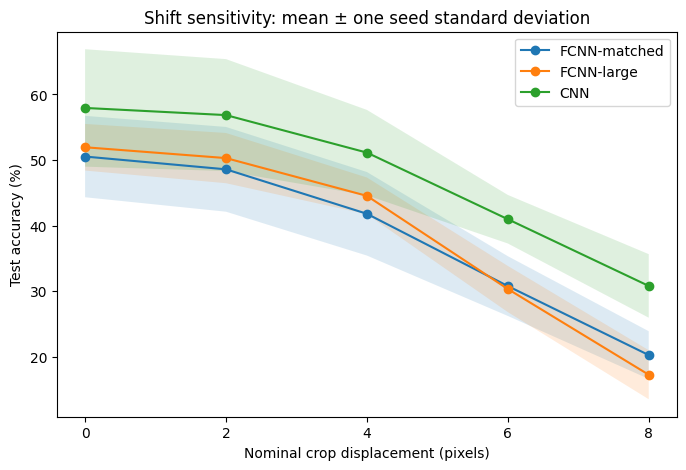

In [21]:
# PART 3.2: Shift the test crops without retraining the models

shift_rng = np.random.default_rng(3200)
# Use the same directions for all models and distances.
angles = shift_rng.uniform(0, 2 * np.pi, len(test_idx))
directions = np.column_stack([np.sin(angles), np.cos(angles)])
shift_rows = []
for d in [0, 2, 4, 6, 8]:
    offsets = np.rint(d * directions).astype(int)
    assert np.all((10 + offsets >= 0) & (10 + offsets + 48 <= 69))
    shifted_images = x_test if d == 0 else standardise(prepare_images(test_idx, offsets))
    for run in baseline_runs:
        probabilities = (baseline_probabilities[(run["name"], run["seed"])] if d == 0
                         else predict(load_model(run), shifted_images))
        predicted = probabilities.argmax(axis=1)
        shift_rows.append({"model": run["name"], "seed": run["seed"], "displacement": d,
                           "mean_actual_distance": np.linalg.norm(offsets, axis=1).mean(),
                           "accuracy": accuracy_score(y_test, predicted),
                           "balanced_accuracy": balanced_accuracy_score(y_test, predicted)})
shift_results = pd.DataFrame(shift_rows)
display(shift_results.groupby("displacement")["mean_actual_distance"].first().to_frame())

fig, ax = plt.subplots(figsize=(8, 5))
for name in MODEL_NAMES:
    grouped = shift_results[shift_results.model == name].groupby("displacement")["accuracy"]
    mean, sd = grouped.mean() * 100, grouped.std(ddof=1) * 100
    ax.plot(mean.index, mean, "o-", label=name)
    ax.fill_between(mean.index, mean - sd, mean + sd, alpha=0.15)
ax.set(xlabel="Nominal crop displacement (pixels)", ylabel="Test accuracy (%)",
       title="Shift sensitivity: mean ± one seed standard deviation", xticks=[0, 2, 4, 6, 8])
ax.legend()
plt.show()


### 3.3. Scrambled-image results

One shuffle (seed **2026**) is shared by training, validation, and test, keeping each pixel's color channels together. Both models are retrained with seed **11** and compared with their seed-11 baselines.

| Model | Original accuracy (%) | Scrambled accuracy (%) | Change (points) |
|---|---:|---:|---:|
| FCNN-matched | 52.63 | 50.40 | -2.23 |
| CNN | 55.05 | 63.68 | +8.63 |

The FCNN barely changes, as expected. **The CNN improves, so my prediction was wrong.** Its dense layer can still combine shuffled information. One run doesn't show that scrambling helps: baseline CNN scores vary by about nine points, and rare validation images affect early stopping. I would need more seeds and shuffles to check.


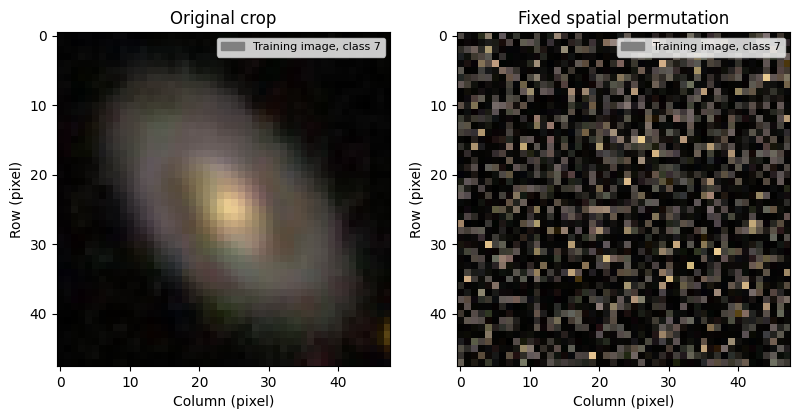

,model,seed,baseline_accuracy,scrambled_accuracy,accuracy_change_pp,selected_epoch
0,FCNN-matched,11,0.526316,0.503978,-2.233782,10
1,CNN,11,0.550490,0.636781,8.629131,12


In [23]:
# PART 3.3: Compare scrambled and original images at the same seed

raw_crop = images[train_idx[0], 10:58, 10:58]
raw_scrambled = raw_crop.reshape(-1, 3)[permutation].reshape(48, 48, 3)
fig, axes = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)
for ax, img, title in zip(axes, [raw_crop, raw_scrambled], ["Original crop", "Fixed spatial permutation"]):
    ax.imshow(img)
    ax.set(xlabel="Column (pixel)", ylabel="Row (pixel)", title=title)
    ax.legend(handles=[Patch(color="gray", label=f"Training image, class {labels[train_idx[0]]}")], fontsize=8)
plt.show()

x_test_scrambled = scramble(x_test)
scrambled_rows = []
for run in scrambled_runs:
    probabilities = predict(load_model(run), x_test_scrambled)
    baseline = baseline_results[(baseline_results.model == run["name"]) & (baseline_results.seed == 11)].iloc[0]
    accuracy = accuracy_score(y_test, probabilities.argmax(axis=1))
    scrambled_rows.append({"model": run["name"], "seed": 11,
                           "baseline_accuracy": baseline.accuracy, "scrambled_accuracy": accuracy,
                           "accuracy_change_pp": 100 * (accuracy - baseline.accuracy),
                           "selected_epoch": run["best_epoch"]})
scrambled_results = pd.DataFrame(scrambled_rows)
display(scrambled_results)
del x_test_scrambled


## Part 4 - Discussion


### 4(a). Performance and speed

I would pick the CNN for accuracy, but it takes much longer on this CPU. It reaches the target in all three runs, versus one and two for the FCNNs. It isn't faster in wall-clock time.

| Model | Accuracy (%) | Balanced accuracy (%) | Parameters | MACs/image | Seconds/epoch | Seconds to target |
|---|---:|---:|---:|---:|---:|---:|
| FCNN-matched | 50.53 ± 6.21 | 44.73 ± 2.26 | 168,162 | 168,064 | 1.61 ± 0.49 | 27.96 (one run) |
| FCNN-large | 51.95 ± 3.56 | 44.72 ± 0.54 | 1,803,914 | 1,803,520 | 2.59 ± 0.36 | 15.56 ± 5.14 |
| CNN | 57.95 ± 8.96 | 52.04 ± 4.26 | 171,754 | 6,451,840 | 36.26 ± 0.67 | 466.31 ± 100.69 |

Mean ± sample standard deviation; parameters and MACs are fixed. Target times include only successful runs (one for FCNN-matched).


In [25]:
# PART 4(a): Collect the main results in one table

display(baseline_summary[["accuracy", "balanced_accuracy", "parameters", "MACs",
                         "seconds_per_epoch", "seconds_to_target", "reached_target"]].round(3))


accuracy        balanced_accuracy        parameters       \
                 mean    std              mean    std       mean  std   
model                                                                   
FCNN-matched    0.505  0.062             0.447  0.023   168162.0  0.0   
FCNN-large      0.519  0.036             0.447  0.005  1803914.0  0.0   
CNN             0.579  0.090             0.520  0.043   171754.0  0.0   

                   MACs      seconds_per_epoch        seconds_to_target  \
                   mean  std              mean    std              mean   
model                                                                     
FCNN-matched   168064.0  0.0             1.605  0.490            27.961   
FCNN-large    1803520.0  0.0             2.595  0.360            15.557   
CNN           6451840.0  0.0            36.264  0.673           466.315   

                      reached_target  
                  std          count  
model                                 
FCNN-matched      NaN              1  
FCNN-large      5.139              2  
CNN           100.685              3

### 4(b). What about these images helps?

The CNN handled shifts better. The crop kept **91%** of the average image's light, so most structure is near the center. Small filters can find parts of arms and bulges for later layers to combine, though scrambling didn't show this benefit. Noise (**2.97–5.99 counts**) and contamination justify preprocessing; I didn't separately test pooling.


### 4(c). Five magnitudes

I would use a small FCNN for $(u,g,r,i,z)$: there is no 2D image structure. A 1D CNN assumes patterns can move between bands without changing meaning, which doesn't fit five fixed, unevenly spaced filters. It makes more sense for a densely sampled spectrum.


### 4(d). What I would change first

I would check labels and get more rare-class examples first. The CNN misses both class-5 images and gets only **20.6%** of class 0 right, despite its reasonable S/N. Noise, clipping, resolution, and other sources limit what is visible. A bigger network can't recover missing detail or settle unclear labels.


# AI Usage

I used OpenAI Codex for help with the theory, code, debugging, and writing. The numbers come from running the notebook.
